###Hein Htet
###INST 414

### Why Do Online Shoppers Browse but Never Buy?
## Discovering browsing patterns with K-Means clustering

**Research question:** *What distinct browsing patterns exist among online shopping sessions, how do purchase rates differ across those patterns, and which group should an e-commerce company investigate first?*

**Stakeholder:** An e-commerce **product manager** responsible for improving the shopping experience and increasing the percentage of visits that end in a purchase.

**Decision this informs:** Which browsing patterns should the team investigate first, and where should it consider testing improvements such as clearer product information or changes to landing pages?

**Unit of analysis:** A **shopping session** is one visit to an online store in which someone may view pages, explore products, and possibly make a purchase. **Each row represents one session, not a unique customer.** A visitor could have multiple sessions.

**Important:** Clustering identifies associations in browsing behavior. It cannot tell us *why* a particular person decided not to buy.

## 1. Data source and collection

**Source:** [UCI Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)  
**Citation:** Sakar, C. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q

I loaded the dataset directly from the UCI Machine Learning Repository using the Python **`ucimlrepo`** library (`fetch_ucirepo(id=468)`). I combined the returned features and target (`Revenue`) into one pandas DataFrame. No manual scraping was required.

The downloaded data contains **12,330 sessions and 18 columns**. Its fields describe page counts and durations (`ProductRelated`, `Informational`, `Administrative`, and their durations), engagement metrics (`BounceRates`, `ExitRates`, `PageValues`), context (`Month`, `Weekend`, `VisitorType`, `TrafficType`, `Region`, `Browser`, `OperatingSystems`, `SpecialDay`), and whether the session ended in a purchase (`Revenue`).

These fields are relevant because they measure what visitors do during a shopping session and let us compare **conversion rates after** discovering groups. All 12,330 valid sessions are used in the final clustering model; only the *silhouette-score calculation* uses a random sample of up to 2,000 sessions for speed.

The clustering uses only **six browsing-behavior features**, explained in Section 3. `Revenue` is **not** used to construct the clusters.

### Install and import libraries
Run the next cell once. In some notebook environments, a kernel restart may be needed after installation.

In [1]:
%pip install -q ucimlrepo pandas numpy scikit-learn matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

### Load and preview the dataset

In [3]:
dataset = fetch_ucirepo(id=468)
df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)

print("Dataset shape (rows, columns):", df.shape)
display(df.head())

Dataset shape (rows, columns): (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2. Explore and validate the input data

First, inspect the column types, missing values, numerical ranges, identical records, and purchase outcomes. These checks help us avoid clustering invalid or incomplete data.

**Why check repeated rows?** Two shopping sessions can have identical recorded values. Since this dataset does not give us a unique session ID, identical rows are not automatically proof of duplicate sessions.

In [4]:
df.info()
display(df.describe(include="all").T)

print("Missing values by column:")
display(df.isna().sum().to_frame("Missing"))

print("Identical rows:", df.duplicated().sum())
print("Purchase outcome counts:")
display(df["Revenue"].value_counts(dropna=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


Missing values by column:


,Missing
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


Identical rows: 125
Purchase outcome counts:


,count
Revenue,
False,10422
True,1908


**Observed data-quality results.** The dataset loaded with **12,330 rows and 18 columns**. Every column shows **0 missing values**. The dataset has **125 identical rows**, which I kept because multiple visits can share the same recorded characteristics. Of the 12,330 sessions, **1,908 ended with a purchase** and **10,422 did not**—an overall conversion rate of about **15.5%**.

## 3. Choose features and clean the data

The question is about **browsing behavior**, so I chose six numerical features that describe product engagement, information seeking, and exiting a website:

| Feature | Why it matters |
|---|---|
| `ProductRelated` | Number of product-related pages viewed; indicates how extensively a visitor explores products. |
| `ProductRelated_Duration` | Total time recorded on product-related pages; indicates depth of product engagement. |
| `Informational` | Number of informational pages viewed; captures use of non-product information. |
| `Informational_Duration` | Time recorded on informational pages; captures attention to information pages. |
| `BounceRates` | Page-level bounce-rate metric associated with the session; may reflect limited engagement. |
| `ExitRates` | Page-level exit-rate metric associated with the session; may reflect how readily visitors leave. |

I did **not** use `Revenue`, because that is the purchase outcome I want to compare **after** clustering; including it would make the comparison circular. I also excluded `PageValues` to avoid relying on a transaction-related metric, and left out other available fields to keep the model focused and interpretable.

**Cleaning rules:** Remove rows with missing clustering features or missing `Revenue`, reject negative values, and require bounce and exit rates between 0 and 1. Preserve otherwise valid identical records, because they may be separate sessions with the same recorded measurements.

In [5]:
features = [
    "ProductRelated", "ProductRelated_Duration",
    "Informational", "Informational_Duration",
    "BounceRates", "ExitRates"
]

rows_before = len(df)
df = df.dropna(subset=features + ["Revenue"]).copy()

valid_values = (df[features] >= 0).all(axis=1)
valid_rates = df["BounceRates"].between(0, 1) & df["ExitRates"].between(0, 1)
df = df.loc[valid_values & valid_rates].copy()

df["Revenue"] = df["Revenue"].astype(int)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("Rows removed:", rows_before - len(df))
print("Overall purchase rate: {:.1f}%".format(df["Revenue"].mean() * 100))

Rows before cleaning: 12330
Rows after cleaning: 12330
Rows removed: 0
Overall purchase rate: 15.5%


**Cleaning result.** The filtering rules removed **0 sessions**: all 12,330 rows passed the selected missing-value and validity checks. The purchase outcome was converted from Boolean (`True`/`False`) to numeric (`1`/`0`) to make conversion rates straightforward to calculate.

### Check feature distributions

Histograms help show whether the features are skewed or contain unusually large values. For example, a few long browsing sessions could dominate Euclidean distance if raw durations are used. In the next step, I reduce skew in page counts and durations before scaling all six features.

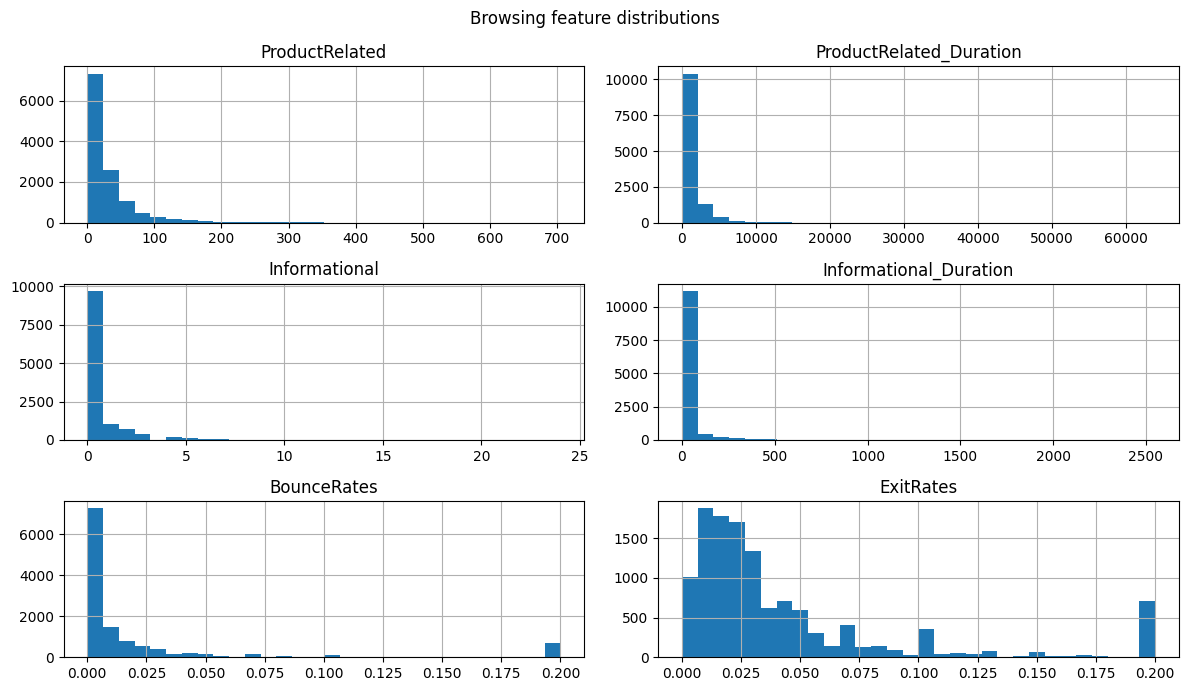

In [6]:
df[features].hist(bins=30, figsize=(12, 7))
plt.suptitle("Browsing feature distributions")
plt.tight_layout()
plt.show()

## 4. Define similarity and prepare the features

**Similarity metric: Euclidean distance.** Two sessions are considered more similar when their six transformed, standardized feature values are closer together. K-Means assigns each session to the nearest cluster center and iteratively updates those centers.

Before calculating distances, I apply **`np.log1p()`** to the four page-count and duration variables to reduce right skew and the influence of extremely large values. I then use **`StandardScaler`** on all six features, so differences in measurement units (pages, time, and rates) do not automatically give one variable the most weight.

This means the algorithm clusters sessions by **relative browsing patterns**, not by the raw difference between page counts and durations.

In [7]:
X = df[features].copy()

# Compress large counts and durations before scaling.
skewed_features = [
    "ProductRelated", "ProductRelated_Duration",
    "Informational", "Informational_Duration"
]
X[skewed_features] = np.log1p(X[skewed_features])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Rows and clustering features:", X_scaled.shape)
print("All scaled values are finite:", np.isfinite(X_scaled).all())

Rows and clustering features: (12330, 6)
All scaled values are finite: True


## 5. Choose the number of clusters (k)

I tested **k = 2 through 8** rather than deciding the number of groups in advance. To compare choices, I calculated:

- **Inertia (elbow method):** The total squared distance of sessions from their assigned cluster centers. Lower is better, but inertia naturally decreases as k increases.
- **Silhouette score:** How well sessions fit within their assigned cluster compared with another cluster; larger scores generally mean clearer separation.

For speed, each silhouette score is based on a **reproducible random sample of up to 2,000 sessions**, while K-Means itself is fitted using **all cleaned sessions** at each k.

In [8]:
results = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled, labels, sample_size=min(2000, len(df)), random_state=42
    )
    results.append({"k": k, "Inertia": model.inertia_, "Silhouette": score})

scores = pd.DataFrame(results)
display(scores.round(3))

,k,Inertia,Silhouette
0,2,45168.848,0.617
1,3,22729.274,0.574
2,4,15725.516,0.439
3,5,13354.656,0.392
4,6,11601.899,0.365
5,7,10084.318,0.357
6,8,9188.670,0.357


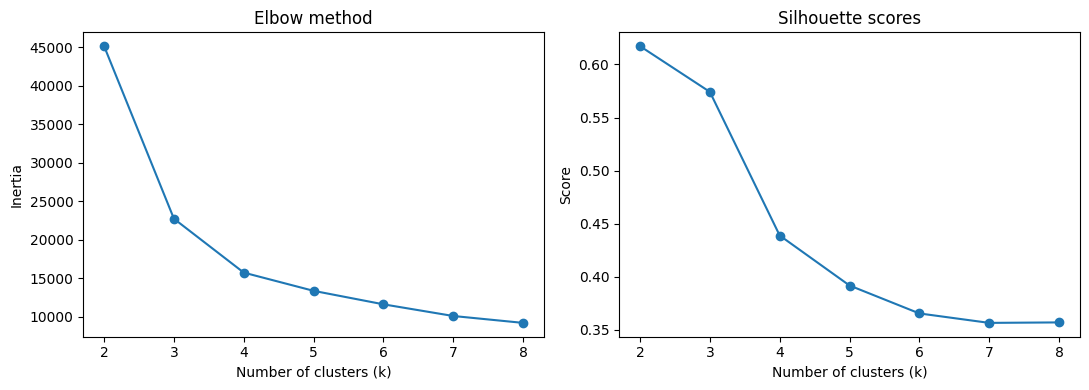

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(scores["k"], scores["Inertia"], marker="o")
axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia")

axes[1].plot(scores["k"], scores["Silhouette"], marker="o")
axes[1].set(title="Silhouette scores", xlabel="Number of clusters (k)", ylabel="Score")

plt.tight_layout()
plt.show()

**Reading the plots:** The silhouette line peaks at **k = 2 (0.617)** and declines at **k = 3 (0.574)** and beyond. However, inertia still falls substantially from k = 2 to k = 3, so the elbow plot alone does not uniquely determine k = 2. The choice below weighs **separation and interpretability** more heavily than creating extra smaller groups.

### Selected k = 2: justification based on actual results

I selected **k = 2** because it had the **highest sampled silhouette score, 0.617**, among the tested options. For comparison, the silhouette score was **0.574 at k = 3** and **0.439 at k = 4**, decreasing further for larger values. This suggests the two-cluster solution gives the clearest separation according to this metric.

The **elbow plot is less definitive**: inertia falls from **45,168.848 at k = 2** to **22,729.274 at k = 3**, and to **15,725.516 at k = 4**, then improves more slowly after that. So **k = 3 or 4 would also be plausible from the elbow perspective**. I prioritized the best observed silhouette score and a simple, interpretable division of sessions for this introductory analysis.

**Trade-off:** k = 2 separates high-exit sessions from a much larger group of other sessions. It does **not** necessarily reveal all distinct customer behaviors. A future analysis could test k = 3 to see whether the larger group contains useful subgroups. The silhouette scores were **sampled**, not computed on every session.

In [10]:
suggested_k = int(scores.loc[scores["Silhouette"].idxmax(), "k"])
k = suggested_k  # You may change this after reviewing the plots.

print("Best k by sampled silhouette score:", suggested_k)
print("Selected k for the final model:", k)

Best k by sampled silhouette score: 2
Selected k for the final model: 2


## 6. Run K-Means on all sessions

With **k = 2**, I fit K-Means on the **six standardized features for all 12,330 sessions**. The returned `Cluster` labels (`0` and `1`) are arbitrary numeric identifiers, not meaningful descriptions. I assign descriptive names only after reviewing the original-scale feature values and conversion rates.

In [11]:
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

clustered = df.copy()
clustered["Cluster"] = cluster_labels

print("Sessions in each cluster:")
display(clustered["Cluster"].value_counts().sort_index())

Sessions in each cluster:


,count
Cluster,
0,989
1,11341


**Cluster sizes.** The model assigned **989 sessions to Cluster 0 (8.0%)** and **11,341 sessions to Cluster 1 (92.0%)**. This is a notably **uneven split**. That does not invalidate the analysis, but it means k = 2 creates one smaller, distinctive group and one broad group that could contain further patterns.

### Figure: Visualizing the K-Means clusters

The scatter plot below shows **each shopping session as a point**, similar to the example graph. I chose two easy-to-interpret dimensions:

- **X-axis:** Scaled `log(1 + ProductRelated)` — how many product pages the visitor browsed (log-transformed, then standardized).
- **Y-axis:** Scaled `ExitRates` — the session's exit-rate metric (standardized).

**Color** shows the cluster assigned by K-Means. **Shape** shows whether the session ended in a purchase: a circle means **no purchase**, and a triangle means **purchase**. Large white circles with black outlines mark the **cluster centers (centroids)**; their coordinates are the centers' values on these two axes.

**Important:** K-Means originally grouped sessions using **all six features**. This plot displays only *two* of those features for readability, so any overlapping points on the chart do not necessarily overlap in the full six-dimensional data. `Revenue` is shown using marker shapes **only for interpretation**; it was **not used** in clustering.

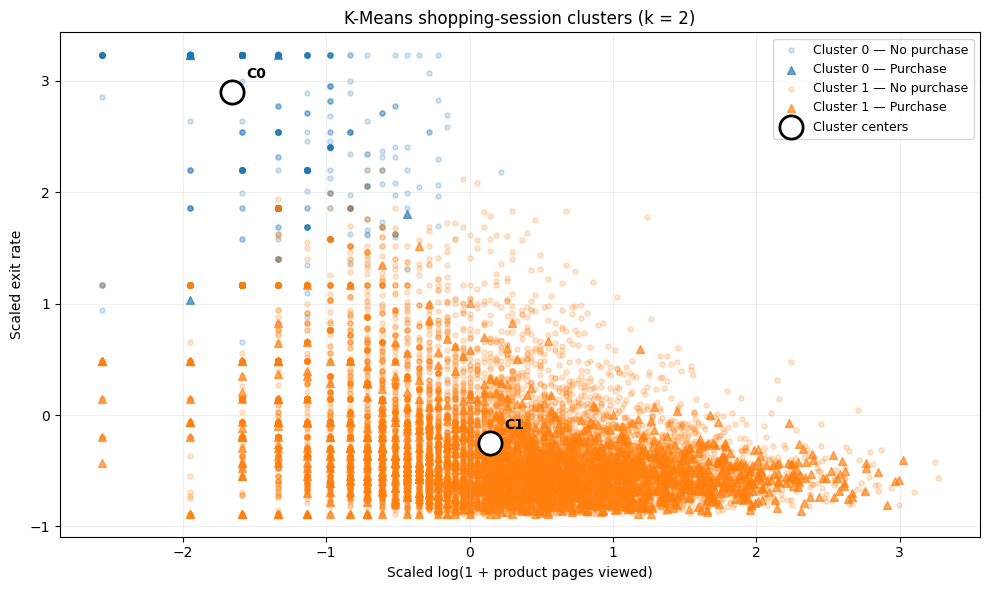

In [12]:
# Plot the clusters using two of our six scaled features.
x_feature = "ProductRelated"
y_feature = "ExitRates"

plot_df = pd.DataFrame({
    "x": X_scaled[:, features.index(x_feature)],
    "y": X_scaled[:, features.index(y_feature)],
    "Cluster": cluster_labels,
    "Purchased": clustered["Revenue"].astype(bool).to_numpy()
})

plt.figure(figsize=(10, 6))

# Colors show clusters; circles/triangles show whether a purchase occurred.
for cluster_id in sorted(plot_df["Cluster"].unique()):
    for purchased, marker in [(False, "o"), (True, "^")]:
        points = plot_df[
            (plot_df["Cluster"] == cluster_id)
            & (plot_df["Purchased"] == purchased)
        ]
        plt.scatter(
            points["x"], points["y"],
            s=14 if not purchased else 32,
            alpha=0.20 if not purchased else 0.65,
            marker=marker,
            color=f"C{cluster_id}",
            label=f"Cluster {cluster_id} — {'Purchase' if purchased else 'No purchase'}"
        )

# Draw cluster centers for the two displayed features.
centers = kmeans.cluster_centers_
center_x = centers[:, features.index(x_feature)]
center_y = centers[:, features.index(y_feature)]
plt.scatter(
    center_x, center_y, s=280, marker="o",
    facecolors="white", edgecolors="black", linewidths=2,
    label="Cluster centers", zorder=5
)
for cluster_id in range(k):
    plt.annotate(f"C{cluster_id}", (center_x[cluster_id], center_y[cluster_id]),
                 xytext=(10, 10), textcoords="offset points", fontweight="bold")

plt.title(f"K-Means shopping-session clusters (k = {k})")
plt.xlabel("Scaled log(1 + product pages viewed)")
plt.ylabel("Scaled exit rate")
plt.grid(alpha=0.2)
plt.legend(fontsize=9, loc="best")
plt.tight_layout()
plt.show()

**Interpretation of the cluster scatter plot:**

- **Cluster 0 — quick-exit / low-engagement sessions:** These sessions tend to appear toward the **left** (fewer product pages) and **top** (higher exit-rate values). This matches the cluster's median of **1 product page** and **0.20 exit rate** in the summary table below.
- **Cluster 1 — product-browsing / more-engaged sessions:** These sessions tend to appear farther **right** (more product browsing) and **lower** (lower exit rates). The summary table shows a median of **20 product pages** and **0.02 exit rate** for this group.
- The **large outlined circles** are the cluster centroids, representing the mean position of each cluster in standardized feature space, *not* actual shopping sessions. Their separation helps illustrate how the two groups differ along these particular features.
- The **triangles** indicate sessions that ended in purchases. Purchase outcomes were **not part of the clustering process**, so this is a descriptive comparison. The conversion-rate chart later in the notebook measures the difference more clearly.

**What this figure cannot establish:** This is a **two-feature view of a six-feature model**. It does not prove that the clusters are perfectly separated in the complete dataset or explain why a visitor did not purchase. The selected k is justified using the **silhouette scores and inertia from all six features**, not this scatter plot alone.

## 7. Characterize the clusters

To explain the clusters in everyday terms, I compare the **median** feature values in their original units, plus their sizes and purchase conversion rates. Medians are less affected by unusual extreme sessions than means.

`PurchaseRatePct` is calculated from `Revenue` **after** the clusters have been assigned. This is important: the algorithm did not have access to purchase labels when forming the groups.

In [13]:
summary = clustered.groupby("Cluster")[features].median().round(2)
summary.insert(0, "Sessions", clustered.groupby("Cluster").size())
summary["SharePct"] = (summary["Sessions"] / len(clustered) * 100).round(1)
summary["PurchaseRatePct"] = (
    clustered.groupby("Cluster")["Revenue"].mean() * 100
).round(1)

display(summary)

,Sessions,ProductRelated,ProductRelated_Duration,Informational,Informational_Duration,BounceRates,ExitRates,SharePct,PurchaseRatePct
Cluster,,,,,,,,,
0,989,1.0,0.00,0.0,0.0,0.2,0.20,8.0,0.5
1,11341,20.0,689.06,0.0,0.0,0.0,0.02,92.0,16.8


**Interpretation of the summary:**

- **Cluster 0 (989 sessions, 8.0%)** has a median of **1 product page**, **0.00 product-page duration**, **0.20 bounce rate**, **0.20 exit rate**, and a **0.5% purchase rate**. A useful descriptive label is **quick-exit / low-engagement sessions**.
- **Cluster 1 (11,341 sessions, 92.0%)** has a median of **20 product pages**, **689.06 product-page duration**, **0.00 bounce rate** (rounded), **0.02 exit rate**, and a **16.8% purchase rate**. A useful label is **product-browsing / more-engaged sessions**.

The two clusters both have **0 median informational pages and 0 median informational duration**, so those variables do not distinguish the *typical* session in these two clusters. This does not mean every session had zero informational activity.

### Figure: Purchase rates by cluster

The two groups differ sharply in observed conversion: **0.5% for Cluster 0** versus **16.8% for Cluster 1**, a gap of **16.3 percentage points**. Both rates are observed associations, not evidence that any one browsing characteristic caused a purchase or abandonment.

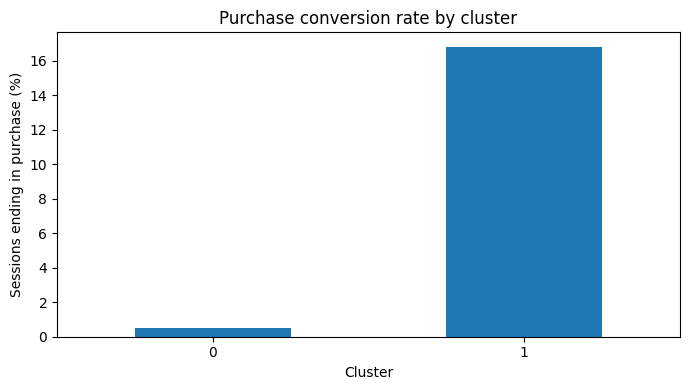

In [14]:
summary["PurchaseRatePct"].plot.bar(figsize=(7, 4))
plt.title("Purchase conversion rate by cluster")
plt.xlabel("Cluster")
plt.ylabel("Sessions ending in purchase (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Figure takeaway:** Cluster 1's conversion rate is **16.3 percentage points higher** than Cluster 0's. Nevertheless, **83.2% of Cluster 1 sessions still did not end in a purchase**. These rates describe differences between groups; they do not show that increasing browsing time would cause more purchases.

### Figure: Cluster behavior heatmap

The heatmap displays each cluster's average position **relative to the overall average** for the six transformed and standardized features. A positive value indicates above-average values; a negative value indicates below-average values.

Along with the medians above, this figure helps show that **Cluster 0 stands out for high bounce/exit metrics and very limited product browsing**, while **Cluster 1 has more product engagement and lower exit metrics**. The colors represent standardized differences, **not** raw page counts, time, or purchase rates.

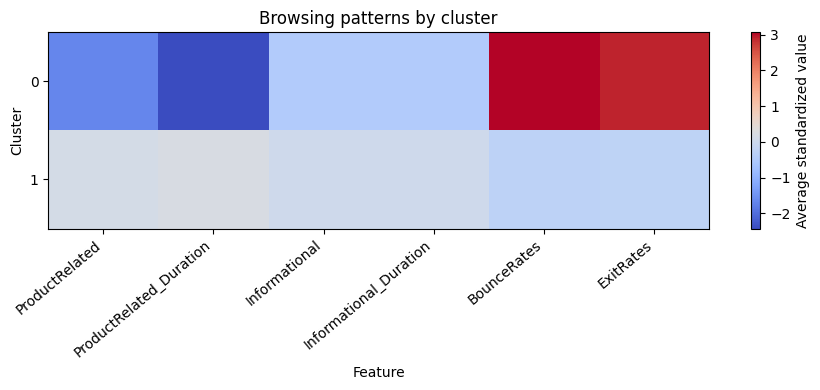

In [15]:
scaled_data = pd.DataFrame(X_scaled, columns=features, index=clustered.index)
scaled_data["Cluster"] = clustered["Cluster"]
cluster_means = scaled_data.groupby("Cluster")[features].mean()

plt.figure(figsize=(9, 4))
plt.imshow(cluster_means, aspect="auto", cmap="coolwarm")
plt.colorbar(label="Average standardized value")
plt.xticks(range(len(features)), features, rotation=40, ha="right")
plt.yticks(range(k), cluster_means.index)
plt.xlabel("Feature")
plt.ylabel("Cluster")
plt.title("Browsing patterns by cluster")
plt.tight_layout()
plt.show()

**Heatmap takeaway:** The plot reinforces the difference between **high bounce/exit and low product browsing in Cluster 0** versus **more product browsing and lower bounce/exit in Cluster 1**. Since the heatmap uses standardized transformed values, use the original-unit median table—not the heatmap colors—when writing specific numbers in the article.

### Two representative sessions from each cluster

The rubric asks for at least **two actual data points in every cluster**. The code chooses the **two sessions nearest each cluster centroid** in the scaled six-feature space. The index on the left is a **dataset row index, not a customer ID**.

Because these examples are selected for their browsing behavior, they are **not** guaranteed to represent the cluster's average purchase outcome.

In [16]:
# Distance from each session to its assigned cluster center.
clustered["DistanceToCenter"] = np.linalg.norm(
    X_scaled - kmeans.cluster_centers_[cluster_labels], axis=1
)

examples = (
    clustered.sort_values("DistanceToCenter")
    .groupby("Cluster", group_keys=False)
    .head(2)
)

display(examples[["Cluster"] + features + ["Revenue"]].round(2))

,Cluster,ProductRelated,ProductRelated_Duration,Informational,Informational_Duration,BounceRates,ExitRates,Revenue
3431,0,3,0.00,0,0.0,0.17,0.18,0
5624,1,20,545.10,0,0.0,0.01,0.03,0
2124,1,19,583.17,0,0.0,0.01,0.03,0
2569,0,4,2.33,0,0.0,0.15,0.16,0


**Representative examples from the actual dataset:**

| Cluster | Dataset row | Product pages | Product duration | Bounce rate | Exit rate | Purchased? |
|---|---:|---:|---:|---:|---:|---|
| 0 | **3431** | 3 | 0.00 | 0.17 | 0.18 | No |
| 0 | **2569** | 4 | 2.33 | 0.15 | 0.16 | No |
| 1 | **5624** | 20 | 545.10 | 0.01 | 0.03 | No |
| 1 | **2124** | 19 | 583.17 | 0.01 | 0.03 | No |

The two Cluster 0 examples have very little product engagement and high exit/bounce metrics. The two Cluster 1 examples view many product pages with lower exit/bounce metrics. **All four selected examples happened not to purchase**; this does not mean Cluster 1 has zero buyers. It has a **16.8% overall purchase rate**.

## 8. Validate the clustering output

**Input data checks:** Examine missing values, negative values, invalid rates, and identical records. Ensure the transformed data contains only finite numbers.

**Output checks:** Verify every valid session receives a cluster label, total cluster membership equals the number of cleaned rows, and no requested cluster is empty. Compare K-Means results from two random seeds using **Adjusted Rand Index (ARI)**. Values near **1** indicate very similar assignments (even if the arbitrary labels are swapped).

Validation helps catch data-processing and stability problems, but **does not establish that the clusters capture true underlying customer motivations**.

In [17]:
assert not df[features + ["Revenue"]].isna().any().any()
assert np.isfinite(X_scaled).all()
assert clustered["Cluster"].notna().all()
assert clustered.groupby("Cluster").size().sum() == len(df)
assert clustered["Cluster"].nunique() == k

second_model = KMeans(n_clusters=k, random_state=7, n_init=10)
second_labels = second_model.fit_predict(X_scaled)
stability = adjusted_rand_score(cluster_labels, second_labels)

print("Validation checks passed.")
print("Smallest cluster size:", clustered["Cluster"].value_counts().min())
print("Stability (Adjusted Rand Index):", round(stability, 3))

Validation checks passed.
Smallest cluster size: 989
Stability (Adjusted Rand Index): 1.0


**Validation result:** All assertions passed. The **smallest cluster contains 989 sessions**, so neither cluster is empty or tiny, and **Adjusted Rand Index = 1.0** across two random-seed runs. This indicates stable assignments **for the chosen features and k**, but it does not prove that the segments would generalize to another e-commerce website or that the proposed marketing changes would succeed.

## 9. Results, interpretation, and business recommendations

### Returning to the research question and stakeholder

**Research question:** *What distinct browsing patterns exist among online shopping sessions, how do purchase rates differ across those patterns, and which group should an e-commerce company investigate first?*

**Stakeholder:** The e-commerce **product manager**, whose goal is to improve the online shopping experience and increase the share of visits that result in a purchase.

**Business decision:** Decide which types of browsing sessions deserve further investigation and which website improvements should be tested first. This is a decision about **shopping-session behavior**, not about identifying or tracking individual customers.

### How I formed the groups

I used **K-Means clustering**, an unsupervised learning method that groups observations with similar feature values. Each observation is **one shopping session**. The model uses the following six variables:

| Feature | What it represents | Relevance to the question |
|---|---|---|
| `ProductRelated` | Number of product pages viewed | How extensively the visitor explores products |
| `ProductRelated_Duration` | Recorded duration on product pages | Depth of product-page engagement |
| `Informational` | Number of informational pages viewed | Whether the visitor looks beyond product listings |
| `Informational_Duration` | Recorded duration on informational pages | Extent of informational browsing |
| `BounceRates` | Bounce-rate metric of pages in the session | Whether the visit is associated with limited engagement |
| `ExitRates` | Exit-rate metric of pages in the session | Whether the visited pages tend to be associated with exits |

**Similarity:** K-Means uses **Euclidean distance**—the straight-line distance between feature vectors. In this analysis, sessions whose **six processed feature values** are closer together are considered more similar. These are *behavioral* similarities; two sessions in the same cluster need not come from the same person or have the same purchase outcome.

**Preparing the features:** The four page-count/duration variables were right-skewed, so I applied **`np.log1p(x)` = log(1 + x)** to those four fields. This reduces the influence of extreme counts and durations while keeping zero values valid. I then used **`StandardScaler`** on **all six** features, subtracting each feature's mean and dividing by its standard deviation. Without scaling, variables such as time on pages could dominate distance simply because their numeric scales are much larger than the bounce/exit rates. Both the transformation and the scaling influence what the model considers similar.

I deliberately **excluded `Revenue`** from the clustering input. `Revenue` records whether the session ended in a purchase; including it would make the later comparison of purchase rates circular. Instead, I used that column **only after assigning clusters**, to evaluate the observed conversion rates.

### Why I selected k = 2

I fitted K-Means using **k = 2 through 8**. Each fitted model used all **12,330** valid sessions; the silhouette score was calculated on a reproducible sample of up to **2,000** sessions to keep the analysis manageable. The two criteria were **inertia**, the sum of squared distances to the assigned centers, and **silhouette score**, which evaluates within-group cohesion relative to between-group separation.

| k | Inertia | Sampled silhouette score |
|---:|---:|---:|
| **2** | **45,168.848** | **0.617** |
| 3 | 22,729.274 | 0.574 |
| 4 | 15,725.516 | 0.439 |
| 5 | 13,354.656 | 0.392 |
| 6 | 11,601.899 | 0.365 |
| 7 | 10,084.318 | 0.357 |
| 8 | 9,188.670 | 0.357 |

**I chose k = 2 because it had the highest observed sampled silhouette score (0.617)**. The score declines to **0.574 at k = 3**, indicating less separation according to this metric, and falls further at larger k values. The silhouette result supports describing two broadly different browsing patterns.

**Trade-off with k = 3:** The **elbow plot does not uniquely favor two groups**. Inertia drops substantially from **45,168.848 at k = 2** to **22,729.274 at k = 3**—almost a 50% reduction—and decreases further at k = 4. Thus k = 3 could reveal a meaningful additional subgroup, even though its sampled silhouette score is lower. I retained **k = 2** for its stronger silhouette result and simpler interpretation, while acknowledging that the **92% / 8%** size imbalance means the large cluster may hide other useful patterns. This is a defensible choice, **not proof that exactly two natural customer types exist**.

### What the clusters actually represent

The model produced the following results. The behavior measurements are **medians in their original units**, not the transformed values used for fitting. Conversion rates are calculated *after* clustering.

| Measure | Cluster 0 | Cluster 1 |
|---|---:|---:|
| **Descriptive label** | **Quick-exit / low-engagement** | **Product-browsing / more-engaged** |
| Sessions | **989** | **11,341** |
| Percentage of dataset | **8.0%** | **92.0%** |
| Median product pages viewed | 1 | 20 |
| Median product-page duration | 0.00 | 689.06 |
| Median informational pages | 0 | 0 |
| Median informational duration | 0.00 | 0.00 |
| Median bounce-rate metric | 0.20 | 0.00 (rounded) |
| Median exit-rate metric | 0.20 | 0.02 |
| **Sessions that ended in purchase** | **0.5%** | **16.8%** |

**Cluster 0: Quick-exit / low-engagement sessions.** This smaller group includes **989 sessions**, or **8.0%** of the dataset. Its median session contains **one product-page view**, no recorded product-page duration, and relatively high bounce and exit metrics (both **0.20**). Only **0.5%** of these sessions ended in a purchase. These results are consistent with visitors who interact very little with the website, but the data cannot establish *why* they left.

**Cluster 1: Product-browsing / more-engaged sessions.** This group includes **11,341 sessions**, or **92.0%** of the dataset. Its median session contains **20 product-page views** and **689.06 units of recorded product-page duration**, with a much lower median exit-rate metric (**0.02**). Its purchase rate is **16.8%**. This is much higher than Cluster 0's rate, but **83.2% of these comparatively engaged sessions still did not purchase**. Browsing products extensively is associated with a higher observed conversion rate here, but it is not a guarantee of purchasing.

Both clusters have medians of **zero** for informational-page views and informational-page duration. Those features were still included in K-Means, but they do not distinguish the *typical* sessions based on their medians; some individual sessions can still have nonzero informational activity.

### Four examples from the actual dataset

To illustrate what the groups contain, I selected the **two sessions closest to each fitted centroid** in the six-feature standardized space. The numbers below are **dataset row indices**, not customer IDs; the figures are values from the executed notebook.

| Cluster | Dataset row | Product pages | Product duration | Bounce rate | Exit rate | Purchase? |
|---|---:|---:|---:|---:|---:|---|
| 0 | **3431** | 3 | 0.00 | 0.17 | 0.18 | No |
| 0 | **2569** | 4 | 2.33 | 0.15 | 0.16 | No |
| 1 | **5624** | 20 | 545.10 | 0.01 | 0.03 | No |
| 1 | **2124** | 19 | 583.17 | 0.01 | 0.03 | No |

Rows **3431** and **2569** have very limited recorded product engagement and elevated bounce/exit metrics, making them reasonable examples of Cluster 0. Rows **5624** and **2124** involve about 20 product-page views and much lower bounce/exit metrics, consistent with Cluster 1. All four particular sessions ended without a purchase because the selection method chose sessions near the **behavioral** centers, not sessions representing each cluster's purchase proportions. Cluster 1 as a whole **does contain purchases**.

### Interpreting the three figures

**1. Cluster scatter plot (Section 6).** Each point represents a session. The horizontal axis is **scaled log(1 + product pages viewed)** and the vertical axis is the **scaled exit-rate metric**. Colors identify K-Means clusters, circles identify non-purchases, triangles identify purchases, and the large outlined markers show the centroids. Cluster 0 generally lies toward **fewer product pages and higher exit rates**, while Cluster 1 generally shows **more product browsing and lower exit rates**. Because K-Means fitted **six dimensions** and the scatter plot displays only **two**, any visual overlap does not invalidate the six-feature clusters. The plot itself is **not** evidence of why sessions did not convert.

**2. Conversion-rate bar chart (Section 7).** Cluster 0 converted at **0.5%**, compared with **16.8%** for Cluster 1: a difference of **16.3 percentage points**. This chart directly connects the unsupervised groupings to the stakeholder's question about where purchases happen more or less frequently. It indicates an association, **not** that changing a visitor's page count or exit rate would cause a purchase.

**3. Behavior heatmap (Section 7).** Each cell displays a cluster's **average standardized feature value** relative to the dataset-wide average. It reinforces the profile seen in the median table: Cluster 0 is characterized by **higher bounce/exit metrics and lower product engagement**, whereas Cluster 1 shows **more product browsing and lower bounce/exit metrics**. Heatmap values are *not* original page counts or rates, so the median table is the appropriate source for numerical descriptions.

### Answer to the research question: what should the product manager do?

The analysis answers the first part of the question by identifying **two broad session-level behavior patterns**. It answers the second part by finding that their observed purchase rates differ substantially—**0.5% versus 16.8%**.

The most useful business insight is **not simply that quick-exit sessions seldom convert**. It is that the **much larger, more-engaged cluster still has an 83.2% non-purchase rate**. If the product manager focused only on the lowest-converting cluster, the company would overlook most browsing sessions and many sessions in which visitors explored numerous products without buying.

**My recommended decision is to investigate non-purchasing sessions in Cluster 1 first**, because that group represents **92% of all sessions** and a large volume of non-purchasing visits. The product team could collect additional information about product detail pages, checkout steps, product availability, delivery costs, or usability to identify a specific barrier, then run an **A/B test** of a proposed improvement. The team should separately review **Cluster 0's** landing pages and traffic sources to determine whether people are arriving with mismatched expectations or encountering a usability issue.

These recommendations are **priorities for further investigation, not proven fixes**. High session volume does not by itself establish the highest potential return on investment, and not every browsing session reflects an intention to buy. A test would need to measure whether a particular change actually increases conversion, while checking for unintended effects.

### Validation: making sure the results are reasonable

**Input checks.** The dataset loaded with **12,330 rows and 18 columns** and showed **no missing values**. The code checked for missing clustering inputs and `Revenue`, negative feature values, and bounce/exit metrics outside the range **0 to 1**. **No rows were removed**. It found **125 rows with identical values**, which were retained because two independent sessions can have the same measurements and there is no unique session identifier to verify duplication. I also checked that the **12,330 × 6** transformed matrix contained only finite numerical values.

**Output checks.** Every cleaned session received a label. The cluster totals **989 + 11,341 = 12,330** match the cleaned dataset, and neither group is empty. I compared a second K-Means fit with a different random seed using the **Adjusted Rand Index (ARI)**. The recorded **ARI of 1.0** means the two runs produced equivalent assignments, even though numerical cluster labels can be arbitrary. I also checked the six-feature summary, two representative rows per group, silhouette results, and all three figures for consistency. These checks demonstrate internal consistency and stability **for these settings**, not that the groups are objectively true or universally useful.

**Use of AI assistance.** Although AI assisted with writing the code for downloading, cleaning, and visualizing the data, I verified its accuracy by manually checking the dataset shape and missing-value counts, confirming the cleaning rules removed zero rows, ensuring cluster counts summed to 12,330, spot-checking example sessions against cluster descriptions, and reviewing each figure for consistency with the reported results — so any mistake in the AI-generated code would have shown up in these independent checks.

### Limitations, missing information, and potential bias

1. **The unit is a session, not a person.** A returning customer may generate multiple observations. The data cannot identify individual loyalty, lifetime value, or whether a later visit produced a purchase.
2. **Important context is missing.** The selected fields do not describe cart contents, prices, stock, shipping charges, exact checkout events, users' intentions, or reasons for leaving. They are not enough to diagnose a specific conversion obstacle.
3. **Possible sampling and representation bias.** This dataset reflects a particular historical online retail context; visitor types, traffic sources, and months may be unevenly represented. The results may not hold for every store, marketing campaign, device, or time period. Only **15.5%** of all recorded sessions end in a purchase, so the outcome classes are also imbalanced.
4. **Model assumptions influence the groups.** K-Means with Euclidean distance tends to identify compact groups, and different features, transformations, or scaling choices could produce different assignments. At **k = 2**, one cluster holds **92%** of sessions; the large cluster likely includes variation that a more detailed segmentation could explore.
5. **Clustering cannot establish causation.** Low exit rates and more product browsing are **associated** with higher conversion in this dataset. These results do **not** demonstrate that increasing browsing time, reducing bounce rates, or changing the website will cause visitors to purchase. Those hypotheses require further study or controlled experiments.

**Conclusion.** For this dataset, K-Means provides a reproducible way to separate **short, high-exit sessions** from **more extensive product-browsing sessions**. The findings support prioritizing an investigation into why many apparently engaged sessions do not end in a purchase, followed by experiments to evaluate specific changes. They do not, by themselves, reveal why any individual visitor abandoned a purchase.


###Github Link

https://github.com/Heinlh/online-shopper-kmeans-cluster/tree/main